# 08 — Per-Unit Calibration: What It Buys, and Where It Stops

Notebook 07 ended with one lever and one open number. Both failure directions
— 21.8 % false alarms on unseen healthy bearings, and real damage sitting
below the healthy spread — traced to the same cause, unit-to-unit variation,
and the only mitigation the data supported was a **healthy baseline taken
from the unit itself**. The open question was the price: *how much of a
unit's own healthy data does that take?*

Paderborn cannot answer the whole question, and it is worth being exact about
why. **No bearing is recorded both healthy and damaged**, so a per-unit
baseline can never be built for a damaged bearing. What the dataset *can*
support is three things, and together they settle the matter:

1. **The false-alarm half, measured directly.** Calibrate on the first *k*
   runs of a healthy bearing, then measure false alarms on that same
   bearing's remaining runs. Fully valid — it is one unit throughout.
2. **The sensitivity half, projected.** Decompose the healthy population's
   noise into window, run and unit levels. Per-unit calibration removes
   exactly the unit term; averaging shrinks the window term. That gives a
   principled projection of what each lever is worth.
3. **A check on that projection.** Compare its predicted detection rates
   against the ones notebook 07 actually measured. A model that disagrees
   with measurement on the bearings we care about is a model we must not
   build a twin spec on.

Step 3 is the one that decides the notebook, and it does not go the way
step 2 suggests.

Features are notebook 07's order-band table, extended to **all four
operating conditions** — which also lets us ask whether a per-unit baseline
survives a change of speed or load.

In [1]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.signal import butter, sosfiltfilt, hilbert, get_window
from scipy.stats import norm

DATA_DIR = pathlib.Path("../data/raw/paderborn")
OUT = pathlib.Path("../data/processed")
CONDITIONS = ["N15_M07_F10", "N09_M07_F10", "N15_M01_F10", "N15_M07_F04"]
BASE_COND = "N15_M07_F10"
FS_HIGH_HZ = 64_000
N_BALLS, BALL_D_MM, PITCH_D_MM = 8, 6.75, 29.05
RATIO = BALL_D_MM / PITCH_D_MM
ORD_BPFO, ORD_BPFI = N_BALLS / 2 * (1 - RATIO), N_BALLS / 2 * (1 + RATIO)

BEARINGS = (
    [(f"K00{i}", "Healthy", "healthy") for i in range(1, 7)]
    + [(c, "OR", "artificial") for c in ("KA01", "KA03", "KA05", "KA07")]
    + [(c, "IR", "artificial") for c in ("KI01", "KI03", "KI05", "KI07")]
    + [(c, "OR", "real") for c in ("KA04", "KA15", "KA16", "KA22", "KA30")]
    + [(c, "IR", "real") for c in ("KI04", "KI14", "KI16", "KI17", "KI18", "KI21")]
)
N_KEEP, WIN, N_WIN = 245_760, 16_384, 15
HANN = get_window("hann", WIN)
WIN_FREQS = np.fft.rfftfreq(WIN, 1 / FS_HIGH_HZ)
FLOOR_MASK = (WIN_FREQS > 10) & (WIN_FREQS < 400)
SOS_ENV = butter(4, (1000, 20000), btype="bandpass", fs=FS_HIGH_HZ, output="sos")
ORDER_CENTERS = np.round(np.arange(1.0, 30.0 + 1e-9, 0.5), 2)
HALF_ORDER = 0.25
BAND_COLS = [f"O{c:g}".replace(".", "p") for c in ORDER_CENTERS]
FLAT_MASK = (WIN_FREQS >= 10) & (WIN_FREQS <= 1000)
HF_MASK = (WIN_FREQS >= 1000) & (WIN_FREQS <= 20000)
TOT_MASK = (WIN_FREQS >= 10) & (WIN_FREQS <= 30000)


def load_channels(p):
    p = pathlib.Path(p)
    ch = loadmat(p)[p.stem]["Y"][0, 0][0]
    return {str(c["Name"][0]): c["Data"].squeeze() for c in ch}


def windowed(sig):
    w = sig[: N_WIN * WIN].reshape(N_WIN, WIN).astype(np.float64)
    return w - w.mean(axis=1, keepdims=True)


def power_spectrum(w):
    return np.abs(np.fft.rfft(w * HANN, axis=1)) ** 2


def band_peak_db(spec, hz, floor, halfwidth=4.0):
    m = (WIN_FREQS >= hz - halfwidth) & (WIN_FREQS <= hz + halfwidth)
    return 10 * np.log10(spec[:, m].max(axis=1) / floor)


def run_features(condition, code, run):
    """Identical recipe to notebook 07, parameterised by operating condition."""
    ch = load_channels(DATA_DIR / code / f"{condition}_{code}_{run}.mat")
    vib = ch["vibration_1"][:N_KEEP].astype(np.float64)
    fr = float(ch["speed"].mean()) / 60.0
    bp = sosfiltfilt(SOS_ENV, vib)
    env = np.abs(hilbert(bp))
    espec = power_spectrum(windowed(env - env.mean()))
    efloor = np.median(espec[:, FLOOR_MASK], axis=1)
    edb = 10 * np.log10(espec / efloor[:, None])
    bands = np.empty((N_WIN, len(ORDER_CENTERS)))
    for j, c in enumerate(ORDER_CENTERS):
        m = (WIN_FREQS >= (c - HALF_ORDER) * fr) & (WIN_FREQS < (c + HALF_ORDER) * fr)
        bands[:, j] = edb[:, m].max(axis=1)
    s = espec[:, FLAT_MASK]
    bw = windowed(bp)
    vspec = power_spectrum(windowed(vib))
    out = pd.DataFrame(bands, columns=BAND_COLS)
    out["Env_BPFO_dB"] = band_peak_db(espec, ORD_BPFO * fr, efloor)
    out["Env_BPFI_dB"] = band_peak_db(espec, ORD_BPFI * fr, efloor)
    out["Env_fr_dB"] = band_peak_db(espec, fr, efloor)
    out["Env_Flatness_dB"] = 10 * np.log10(np.exp(np.log(s).mean(axis=1)) / s.mean(axis=1))
    out["Vib_BP_Kurtosis"] = (bw ** 4).mean(axis=1) / (bw ** 2).mean(axis=1) ** 2
    out["Vib_HF_Ratio"] = vspec[:, HF_MASK].sum(axis=1) / vspec[:, TOT_MASK].sum(axis=1)
    out["fr_Hz"], out["Window"] = fr, np.arange(N_WIN)
    return out


def build(condition):
    """Extract one condition, or reuse a cached table if it is already on disk."""
    path = OUT / f"pu_{condition}_envelope_orderbands.csv"
    if path.exists():
        return pd.read_csv(path)
    tabs = []
    for code, cond, dom in BEARINGS:
        for run in range(1, 21):
            f = run_features(condition, code, run)
            f["Code"], f["Condition"], f["Domain"], f["Run"] = code, cond, dom, run
            tabs.append(f)
    d = pd.concat(tabs, ignore_index=True)
    d.to_csv(path, index=False)
    return d


D = {c: build(c) for c in CONDITIONS}
ds = D[BASE_COND]
BANDS, FUND = BAND_COLS, ["Env_BPFO_dB", "Env_BPFI_dB", "Env_fr_dB"]
HEALTHY = [c for c, cond, _ in BEARINGS if cond == "Healthy"]
DAMAGED = [c for c, cond, _ in BEARINGS if cond != "Healthy"]
LABEL = ds.drop_duplicates("Code").set_index("Code")[["Condition", "Domain"]]

C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
CLASS_COLOR = {"Healthy": MUTED, "OR": C_BLUE, "IR": C_ORANGE}
print({c: D[c].shape for c in CONDITIONS})
print("shaft rate (Hz) by condition:",
      {c: round(float(D[c]["fr_Hz"].median()), 1) for c in CONDITIONS})

{'N15_M07_F10': (7500, 71), 'N09_M07_F10': (7500, 71), 'N15_M01_F10': (7500, 71), 'N15_M07_F04': (7500, 71)}
shaft rate (Hz) by condition: {'N15_M07_F10': 25.0, 'N09_M07_F10': 15.0, 'N15_M01_F10': 25.0, 'N15_M07_F04': 25.0}


## Experiment 1 — the calibration budget, measured

The only fully valid experiment on this dataset: fit the baseline on the
first *k* runs of a healthy bearing, set the threshold at the 99th percentile
of those same runs' scores, then measure the false-alarm rate on runs
*k+1 … 20* of **the same bearing**. One unit throughout, so nothing is
confounded — and the held-out runs are later recordings, so run-to-run
variation is included rather than hidden.

Each run is one 4-second recording (15 windows), so *k* runs ≈ 3.8 *k*
seconds of commissioning data. Two reference lines from notebook 07: the
pooled 5-foreign-bearing baseline, and a single foreign bearing.

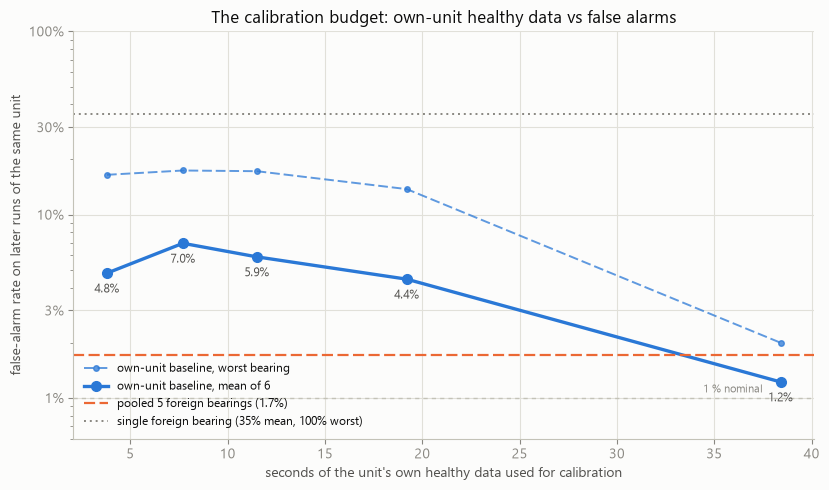

,runs,seconds,mean,worst,best
0,1,3.800000,4.8%,16.5%,0.0%
1,2,7.700000,7.0%,17.4%,1.5%
2,3,11.500000,5.9%,17.3%,0.4%
3,5,19.200000,4.4%,13.8%,0.9%
4,10,38.400000,1.2%,2.0%,0.0%


In [2]:
def fit(X):
    m = np.median(X, axis=0)
    return m, np.maximum(1.4826 * np.median(np.abs(X - m), axis=0), 0.1)


def score(X, b):
    return ((X - b[0]) / b[1]).max(axis=1)


def rows(code, feats=None, runs=None, d=None):
    s = ds if d is None else d
    s = s[s["Code"] == code]
    if runs is not None:
        s = s[s["Run"].isin(runs)]
    return s[BANDS if feats is None else feats].to_numpy()


budget = []
for k in (1, 2, 3, 5, 10):
    fa = []
    for h in HEALTHY:
        cal = range(1, k + 1)
        b = fit(rows(h, runs=cal))
        thr = np.quantile(score(rows(h, runs=cal), b), 0.99)
        fa.append((score(rows(h, runs=range(k + 1, 21)), b) > thr).mean())
    budget.append(dict(runs=k, seconds=round(k * 3.84, 1), mean=np.mean(fa),
                       worst=np.max(fa), best=np.min(fa)))
budget = pd.DataFrame(budget)

pooled, foreign = [], []
for h in HEALTHY:
    others = [c for c in HEALTHY if c != h]
    Xo = np.vstack([rows(c) for c in others])
    b = fit(Xo)
    pooled.append((score(rows(h), b) > np.quantile(score(Xo, b), 0.99)).mean())
    for o in others:
        bo = fit(rows(o))
        foreign.append((score(rows(h), bo) > np.quantile(score(rows(o), bo), 0.99)).mean())
POOLED, FOREIGN, FOREIGN_WORST = np.mean(pooled), np.mean(foreign), np.max(foreign)

# Plotted as mean + worst-case lines rather than a shaded band: the best-case
# bearing hits exactly 0 % at several k, which a log axis cannot render.
fig, ax = plt.subplots(figsize=(8.4, 5.0))
ax.plot(budget["seconds"], budget["worst"], color=C_BLUE, lw=1.4, ls=(0, (5, 2)),
        marker="o", ms=4, alpha=0.75, label="own-unit baseline, worst bearing")
ax.plot(budget["seconds"], budget["mean"], color=C_BLUE, lw=2.4, marker="o", ms=7,
        label="own-unit baseline, mean of 6")
ax.axhline(POOLED, color=C_ORANGE, lw=1.6, ls=(0, (5, 2)),
           label=f"pooled 5 foreign bearings ({POOLED:.1%})")
ax.axhline(FOREIGN, color=MUTED, lw=1.4, ls=(0, (1, 2)),
           label=f"single foreign bearing ({FOREIGN:.0%} mean, {FOREIGN_WORST:.0%} worst)")
ax.axhline(0.01, color=BASE, lw=1, ls=(0, (3, 3)))
ax.text(37.5, 0.0104, "1 % nominal", color=MUTED, fontsize=8, ha="right", va="bottom")
for _, r in budget.iterrows():
    ax.annotate(f"{r['mean']:.1%}", (r["seconds"], r["mean"]), textcoords="offset points",
                xytext=(0, -14), ha="center", fontsize=8.5, color=INK2)
ax.set_yscale("log")
ax.set_ylim(0.006, 1.0)
ax.set_yticks([0.01, 0.03, 0.1, 0.3, 1.0], ["1%", "3%", "10%", "30%", "100%"])
ax.set_xlabel("seconds of the unit's own healthy data used for calibration")
ax.set_ylabel("false-alarm rate on later runs of the same unit")
ax.set_title("The calibration budget: own-unit healthy data vs false alarms")
ax.legend(fontsize=8.5, loc="lower left")
plt.tight_layout()
plt.show()
budget.style.format({"mean": "{:.1%}", "worst": "{:.1%}", "best": "{:.1%}"})

## Reading the calibration budget

- **≈ 38 seconds of the unit's own healthy data is the price.** At 10 runs the
  false-alarm rate is **1.2 % mean / 2.0 % worst-case** — better than the
  pooled five-bearing baseline (1.7 %) and in a different world from a single
  foreign bearing (35.4 % mean, **100 % worst**). For a monitor commissioned
  on a healthy motor this is nothing: ten four-second records.
- **The curve is not monotonic** (4.8 → 7.0 → 5.9 → 4.4 → 1.2 %), and the
  reason matters: at small *k* the binding constraint is not the baseline but
  the **threshold**. A 99th percentile estimated from 15–45 windows is itself
  noisy, and a threshold set too low costs more than a slightly wrong median.
  Anything under about five runs is dominated by that estimation error.
- Practical consequence for the deployment spec: budget **ten recordings, not
  one**, and prefer a parametric threshold over an empirical quantile when
  only a few records are available.
- This settles the false-alarm half. The sensitivity half cannot be measured
  here — no damaged bearing has healthy history — so the next two sections
  build a projection and then test whether it can be trusted.

## Experiment 2 — where does the noise actually live?

Per-unit calibration removes exactly one term: the difference between this
unit's healthy mean and the population's. Whether that is worth anything
depends on its size *relative to the others*. Decompose the healthy
population's variability into three levels — window-to-window inside a run,
run-to-run inside a unit, and unit-to-unit — and the answer falls out.

Env_BPFO_dB      window 3.84 dB   run 0.97 dB   unit 1.55 dB   -> unit is 13.3% of the variance
Env_BPFI_dB      window 3.77 dB   run 1.02 dB   unit 1.51 dB   -> unit is 13.1% of the variance
Env_fr_dB        window 3.69 dB   run 1.01 dB   unit 1.74 dB   -> unit is 17.1% of the variance


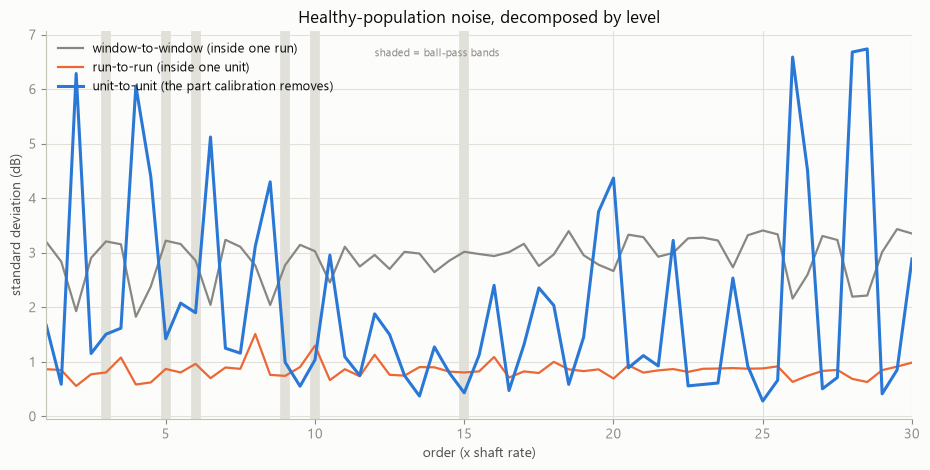


median sd_unit, all 59 bands    : 1.27 dB
median sd_unit, ball-pass bands : 1.23 dB
bands where sd_unit > 3 dB: [2.0, 4.0, 4.5, 6.5, 8.0, 8.5, 19.5, 20.0, 22.0, 26.0, 26.5, 28.0, 28.5]


In [3]:
def three_level(feat, d=None):
    """(sd_window, sd_run, sd_unit) in dB for one feature, healthy bearings only."""
    d = ds if d is None else d
    sw, sr, mu = [], [], []
    for _, g in d[d["Domain"] == "healthy"].groupby("Code"):
        rm = g.groupby("Run")[feat].mean()
        sw.append(g.groupby("Run")[feat].std().mean())
        sr.append(rm.std())
        mu.append(rm.mean())
    return np.mean(sw), np.mean(sr), np.std(mu, ddof=1)


levels = {f: three_level(f) for f in FUND}
for f, (w, r, u) in levels.items():
    tot = w ** 2 + r ** 2 + u ** 2
    print(f"{f:15s}  window {w:4.2f} dB   run {r:4.2f} dB   unit {u:4.2f} dB"
          f"   -> unit is {u ** 2 / tot:5.1%} of the variance")

band_levels = pd.DataFrame([dict(zip(("sd_window", "sd_run", "sd_unit"), three_level(b)))
                            for b in BANDS])
band_levels["order"] = ORDER_CENTERS
BALLPASS = [3.0, 5.0, 6.0, 9.0, 10.0, 15.0]

fig, ax = plt.subplots(figsize=(9.4, 4.8))
for o in BALLPASS:
    ax.axvline(o, color=GRID, lw=7, zorder=0)
ax.plot(band_levels["order"], band_levels["sd_window"], color=MUTED, lw=1.6,
        label="window-to-window (inside one run)")
ax.plot(band_levels["order"], band_levels["sd_run"], color=C_ORANGE, lw=1.6,
        label="run-to-run (inside one unit)")
ax.plot(band_levels["order"], band_levels["sd_unit"], color=C_BLUE, lw=2.2,
        label="unit-to-unit (the part calibration removes)")
ax.text(12.0, 6.6, "shaded = ball-pass bands", color=MUTED, fontsize=8)
ax.set_xlabel("order (x shaft rate)")
ax.set_ylabel("standard deviation (dB)")
ax.set_xlim(1, 30)
ax.set_title("Healthy-population noise, decomposed by level")
ax.legend(fontsize=9, loc="upper left")
plt.tight_layout()
plt.show()

print(f"\nmedian sd_unit, all 59 bands    : {band_levels['sd_unit'].median():.2f} dB")
print(f"median sd_unit, ball-pass bands : "
      f"{band_levels.loc[band_levels['order'].isin(BALLPASS), 'sd_unit'].median():.2f} dB")
print("bands where sd_unit > 3 dB:",
      band_levels.loc[band_levels["sd_unit"] > 3, "order"].tolist())

## Reading the decomposition

- **Window noise dominates everything.** At the fundamentals the standard
  deviations are ≈ **3.8 dB window, 1.0 dB run, 1.5 dB unit** — the term
  per-unit calibration removes is only about **13 % of the total variance**.
  Calibration is not the sensitivity lever; *averaging* is.
- **The unit-to-unit excess is confined to specific bands.** Its median is
  1.27 dB across all 59 bands and 1.23 dB across the ball-pass bands, but it
  spikes above 5 dB at orders 2, 4 and 6.5 — the ≈ 52.7 Hz rig harmonic
  family — and again at orders 26–28.5 (≈ 650–710 Hz). Notebook 07's "healthy
  is two populations" is real but **local**: the groups differ on rig
  harmonics, not on bearing frequencies.
- That explains notebook 07's most puzzling result — why 59 order bands *lost*
  to 3 fundamentals. The extra 56 bands include exactly the ones carrying the
  largest unit-to-unit spread, and a max-pooled detector pays for every one.
  **Physics did not merely narrow the search; it excluded the
  highest-variance bands.**
- Run-to-run noise (1.0 dB) is smaller than unit-to-unit (1.5 dB) but does
  *not* average away within a single recording — it sets a floor that only
  repeated recordings can lower.

## Experiment 3 — the projection: what should each lever be worth?

With the three variances in hand, the effect size of a damaged bearing against
the healthy reference is predictable for any combination of levers. For a
median shift Δ, averaging *M* windows across *R* runs, with or without
per-unit calibration:

    d' = Δ / sqrt( σ_w²/(M·R) + σ_r²/R + [σ_u²] )

where the σ_u term is present for a pooled baseline and **absent** when the
unit is its own reference. Taking d′ ≈ 3 as "separable at a 1 % false-alarm
rate", this says how many of the 19 damaged bearings each lever should reach.

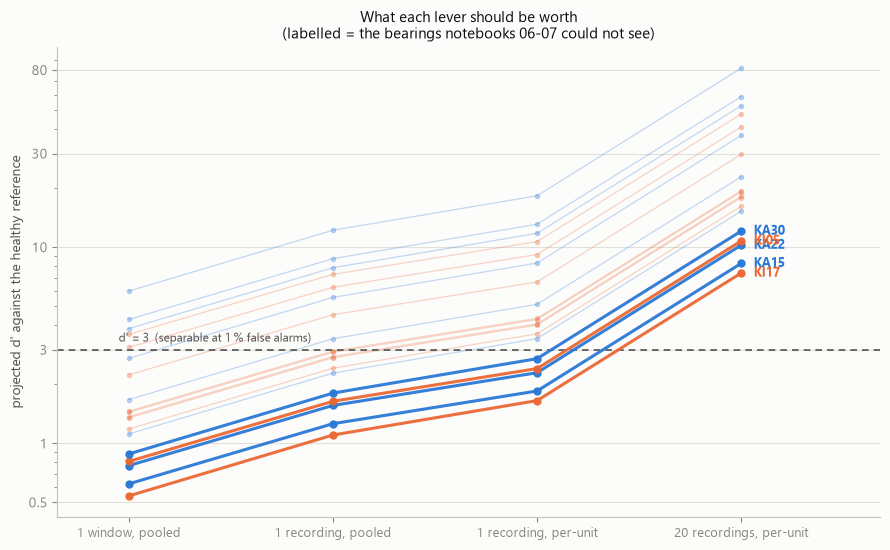

  bearings reaching d' >= 3, 1 window, pooled        :  5/19
  bearings reaching d' >= 3, 1 recording, pooled     :  8/19
  bearings reaching d' >= 3, 1 recording, per-unit   : 14/19
  bearings reaching d' >= 3, 20 recordings, per-unit : 19/19


,Condition,Domain,feature,delta_dB,"1 window, pooled","1 recording, pooled","1 recording, per-unit","20 recordings, per-unit"
Code,,,,,,,,
KI17,IR,real,BPFO,2.3,0.54,1.10,1.65,7.38
KA15,OR,real,BPFI,2.6,0.62,1.26,1.85,8.27
KA22,OR,real,BPFI,3.2,0.77,1.56,2.29,10.25
KI05,IR,artificial,BPFI,3.4,0.81,1.64,2.41,10.76
KA30,OR,real,BPFO,3.8,0.88,1.80,2.70,12.08
KA05,OR,artificial,BPFO,4.8,1.12,2.28,3.42,15.28
KI16,IR,real,BPFO,5.0,1.18,2.42,3.62,16.18
KI07,IR,artificial,BPFI,5.6,1.35,2.73,4.01,17.92
KI21,IR,real,BPFI,5.7,1.37,2.77,4.07,18.18


In [4]:
LEVERS = [("1 window, pooled", 1, 1, False),
          ("1 recording, pooled", 15, 1, False),
          ("1 recording, per-unit", 15, 1, True),
          ("20 recordings, per-unit", 15, 20, True)]
healthy_ref = {f: np.median([ds.loc[ds["Code"] == h, f].median() for h in HEALTHY])
               for f in FUND}

proj = []
for c in DAMAGED:
    best = max(("Env_BPFO_dB", "Env_BPFI_dB"),
               key=lambda f: ds.loc[ds["Code"] == c, f].median() - healthy_ref[f])
    w, r, u = levels[best]
    delta = ds.loc[ds["Code"] == c, best].median() - healthy_ref[best]
    row = {"Code": c, "feature": best.replace("Env_", "").replace("_dB", ""),
           "delta_dB": delta}
    for name, M, R, cal in LEVERS:
        row[name] = delta / np.sqrt(w ** 2 / (M * R) + r ** 2 / R + (0.0 if cal else u ** 2))
    proj.append(row)
proj = pd.DataFrame(proj).set_index("Code").join(LABEL).sort_values(LEVERS[0][0])

# The four bearings notebooks 06-07 could not detect, plus KI05 which behaves
# like them. Labelling only these keeps the right-hand edge readable.
WATCH = ["KA15", "KA22", "KA30", "KI17", "KI05"]
fig, ax = plt.subplots(figsize=(9.0, 5.6))
x = np.arange(len(LEVERS))
for c, row in proj.iterrows():
    vals = [row[n] for n, *_ in LEVERS]
    watched = c in WATCH
    ax.plot(x, vals, color=CLASS_COLOR[row["Condition"]], lw=2.2 if watched else 0.9,
            alpha=0.95 if watched else 0.28, marker="o", ms=5 if watched else 3,
            zorder=4 if watched else 2)
for c in WATCH:
    row = proj.loc[c]
    ax.annotate(c, (x[-1], row[LEVERS[-1][0]]), textcoords="offset points",
                xytext=(9, 0), fontsize=9, color=CLASS_COLOR[row["Condition"]],
                va="center", fontweight="bold")
ax.axhline(3, color=INK2, lw=1.2, ls=(0, (4, 3)))
ax.text(-0.05, 3.3, "d' = 3  (separable at 1 % false alarms)", color=INK2, fontsize=8.5)
ax.set_yscale("log")
ax.set_yticks([0.5, 1, 3, 10, 30, 80], ["0.5", "1", "3", "10", "30", "80"])
ax.set_xticks(x, [n for n, *_ in LEVERS], fontsize=9)
ax.set_xlim(-0.35, len(LEVERS) - 0.32)
ax.grid(axis="x", visible=False)
ax.set_ylabel("projected d' against the healthy reference")
ax.set_title("What each lever should be worth\n"
             "(labelled = the bearings notebooks 06-07 could not see)", fontsize=11)
plt.tight_layout()
plt.show()

for n, *_ in LEVERS:
    print(f"  bearings reaching d' >= 3, {n:24s}: {(proj[n] >= 3).sum():2d}/19")
proj[["Condition", "Domain", "feature", "delta_dB"] + [n for n, *_ in LEVERS]].style.format(
    {"delta_dB": "{:.1f}", **{n: "{:.2f}" for n, *_ in LEVERS}})

## Reading the projection

Taken at face value the projection is encouraging, and it ranks the levers
clearly:

- a single window against a pooled baseline reaches d′ ≥ 3 for **5 of 19**
  bearings;
- averaging one recording (15 windows) takes that to **8 of 19** — the free
  lever notebook 07 measured;
- adding per-unit calibration takes it to **14 of 19**;
- twenty recordings plus calibration reaches **19 of 19**, including KA15
  (d′ 8.3) and KA22 (d′ 10.3).

If that last line were true it would overturn notebooks 06 and 07: the
"physically invisible" bearings would be merely under-averaged. That is
exactly the kind of claim that should not be believed because a formula
produced it — so the next section scores it against numbers we measured.

## Experiment 4 — does the projection survive contact with measurement?

Notebook 07 measured recording-level detection at a 1 % false-alarm rate with
a pooled baseline on the three fundamentals. That is precisely the
"1 recording, pooled" column above, so the projection can be scored against
it bearing by bearing. Re-measured here so the comparison uses one code path.

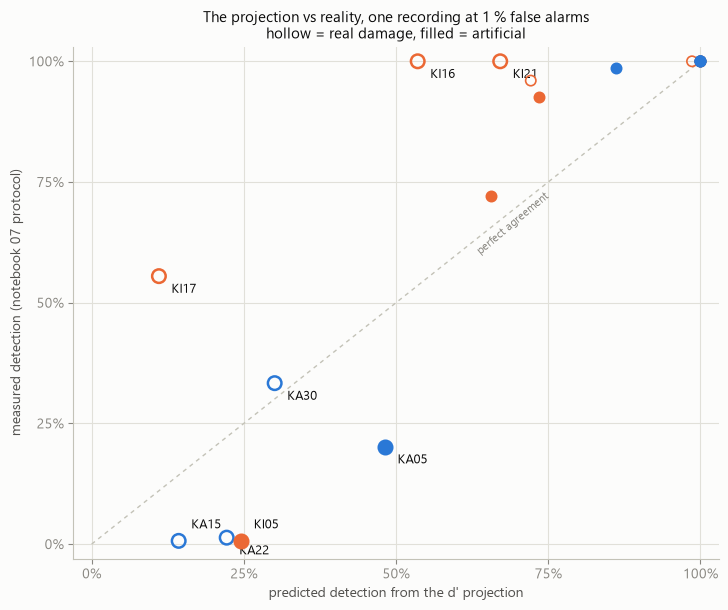

Spearman rank correlation : 0.83
mean absolute error       : 0.15

worst over-predictions (model optimistic):
     Condition      Domain  d_prime  predicted  measured
Code                                                    
KA05        OR  artificial    2.281      0.482     0.202
KI05        IR  artificial    1.638      0.246     0.007
KA22        OR        real    1.560      0.222     0.013
KA15        OR        real    1.259      0.143     0.007


In [5]:
QS = np.unique(np.concatenate([np.linspace(0.5, 0.999, 200), [0.9999]]))
per_fold = {}
for held in HEALTHY:
    tr = ds[(ds["Domain"] == "healthy") & (ds["Code"] != held)]
    b = fit(tr[FUND].to_numpy())
    per_fold[held] = dict(train=score(tr[FUND].to_numpy(), b),
                          per={c: score(rows(c, FUND), b) for c in [held] + DAMAGED})
curve = []
for q in QS:
    fa, det = [], {c: [] for c in DAMAGED}
    for held in HEALTHY:
        e = per_fold[held]
        thr = np.quantile(e["train"], q)
        for c in [held] + DAMAGED:
            flag = (e["per"][c] > thr).reshape(20, N_WIN).mean(axis=1) > 0.5
            (fa if c == held else det[c]).append(flag.mean())
    curve.append(dict(fpr=np.mean(fa), **{c: np.mean(v) for c, v in det.items()}))
curve = pd.DataFrame(curve).sort_values("fpr")

check = proj[["Condition", "Domain"]].copy()
check["d_prime"] = proj[LEVERS[1][0]]
check["predicted"] = norm.sf(norm.isf(0.01) - check["d_prime"])
check["measured"] = [np.interp(0.01, curve["fpr"], curve[c]) for c in check.index]
check["error"] = check["measured"] - check["predicted"]
check = check.sort_values("d_prime")

fig, ax = plt.subplots(figsize=(7.4, 6.2))
ax.plot([0, 1], [0, 1], color=BASE, lw=1, ls=(0, (3, 3)))
ax.text(0.63, 0.60, "perfect agreement", color=MUTED, fontsize=8, rotation=40)
for c, row in check.iterrows():
    # label the big disagreements AND the bearings the argument is about, even
    # where their absolute error looks small because both numbers are near zero
    named = abs(row["error"]) > 0.25 or c in WATCH
    ax.scatter(row["predicted"], row["measured"], s=95 if named else 55, zorder=3,
               facecolors=CLASS_COLOR[row["Condition"]] if row["Domain"] != "real" else "none",
               edgecolors=CLASS_COLOR[row["Condition"]], linewidths=1.8 if named else 1.2)
    if named:
        dy = 9 if c in ("KA15", "KI05") else -12
        ax.annotate(c, (row["predicted"], row["measured"]), textcoords="offset points",
                    xytext=(9, dy), fontsize=9, color=INK)
ax.set_xlim(-0.03, 1.03)
ax.set_ylim(-0.03, 1.03)
ax.set_xticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_xlabel("predicted detection from the d' projection")
ax.set_ylabel("measured detection (notebook 07 protocol)")
ax.set_title("The projection vs reality, one recording at 1 % false alarms\n"
             "hollow = real damage, filled = artificial", fontsize=11)
plt.tight_layout()
plt.show()

print(f"Spearman rank correlation : "
      f"{check['predicted'].corr(check['measured'], method='spearman'):.2f}")
print(f"mean absolute error       : {check['error'].abs().mean():.2f}")
print("\nworst over-predictions (model optimistic):")
print(check.nsmallest(4, "error")[["Condition", "Domain", "d_prime", "predicted", "measured"]]
      .round(3).to_string())

## Reading the check — and the verdict on the lever

- **The projection gets the ordering roughly right (Spearman 0.83) and the
  individual bearings badly wrong (mean absolute error 0.15).**
- **It fails hardest exactly where the question mattered.** KA15: predicted
  14 % detection, measured **0.7 %**. KA22: predicted 22 %, measured **1.3 %**.
  KI05: predicted 25 %, measured 0.7 %. The model is optimistic by more than
  an order of magnitude on the very bearings it claimed averaging and
  calibration would rescue.
- **The reason is that Δ is not what the model assumes.** The projection
  treats each bearing's median shift as a persistent narrowband fault line
  that averaging pulls out of noise. Notebook 06 showed KA15 has *no*
  ball-pass line at all (≤ +1.0 dB on a 20-run averaged spectrum) and KA22's
  energy sits at order 5.5. Their 2.6 and 3.2 dB "shifts" are an offset of the
  whole distribution — this unit sitting high in the population — not a signal
  that grows relative to noise as you average. **Averaging an offset makes you
  confident about the offset, not sensitive to damage.**
- It also errs the other way (KI16 predicted 54 %, measured 100 %; KI17 11 %
  vs 56 %), because a max-pooled multi-band detector exploits structure a
  single-feature Gaussian model cannot represent.
- **Verdict.** Per-unit calibration is worth doing and cheap — ≈ 38 s of
  own-unit healthy data — and it is the only thing that fixes the false-alarm
  half. It is **not** the lever that rescues the invisible bearings, and the
  projection saying otherwise is contradicted by measurement on those exact
  bearings. Notebook 06's physics verdict stands: KA15 and KA30 are not
  under-averaged, they are silent.

## Experiment 5 — shelf life: does a per-unit baseline stay valid?

A baseline is only useful while it still describes the unit. Two ways it goes
stale: **time** (the unit drifts) and **operating point** (the motor changes
speed or load). Both are testable here — the second is why all four
conditions were extracted.

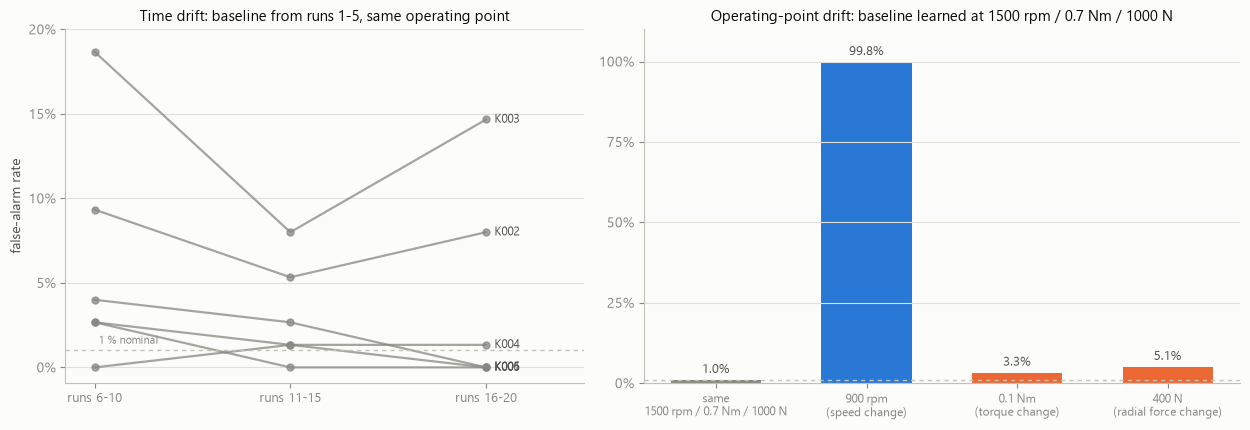

      runs 6-10  runs 11-15  runs 16-20
Code                                   
K001      0.040       0.027       0.000
K002      0.093       0.053       0.080
K003      0.187       0.080       0.147
K004      0.000       0.013       0.013
K005      0.027       0.013       0.000
K006      0.027       0.000       0.000

      N15_M07_F10  N09_M07_F10  N15_M01_F10  N15_M07_F04
Code                                                    
K001         0.01         1.00        0.007        0.030
K002         0.01         1.00        0.043        0.060
K003         0.01         1.00        0.007        0.023
K004         0.01         1.00        0.007        0.070
K005         0.01         0.99        0.003        0.073
K006         0.01         1.00        0.130        0.047


In [6]:
drift = []
for h in HEALTHY:
    b = fit(rows(h, runs=range(1, 6)))
    thr = np.quantile(score(rows(h, runs=range(1, 6)), b), 0.99)
    drift.append(dict(Code=h, **{f"runs {a}-{z}": (score(rows(h, runs=range(a, z + 1)), b) > thr).mean()
                                 for a, z in ((6, 10), (11, 15), (16, 20))}))
drift = pd.DataFrame(drift).set_index("Code")

transfer = []
for h in HEALTHY:
    b = fit(rows(h))
    thr = np.quantile(score(rows(h), b), 0.99)
    transfer.append(dict(Code=h, **{c: (score(rows(h, d=D[c]), b) > thr).mean()
                                    for c in CONDITIONS}))
transfer = pd.DataFrame(transfer).set_index("Code")

fig, (axd, axt) = plt.subplots(1, 2, figsize=(12.6, 4.4),
                               gridspec_kw=dict(width_ratios=[1, 1.15]))
x = np.arange(drift.shape[1])
for h in HEALTHY:
    axd.plot(x, drift.loc[h], marker="o", ms=5, lw=1.6, color=MUTED, alpha=0.75)
    axd.annotate(h, (x[-1], drift.loc[h].iloc[-1]), textcoords="offset points",
                 xytext=(6, 0), fontsize=8.5, color=INK2, va="center")
axd.axhline(0.01, color=BASE, lw=1, ls=(0, (3, 3)))
axd.text(0.02, 0.014, "1 % nominal", color=MUTED, fontsize=8)
axd.set_xticks(x, list(drift.columns), fontsize=9)
axd.set_xlim(-0.15, len(x) - 0.5)
axd.set_yticks([0, .05, .1, .15, .2], ["0%", "5%", "10%", "15%", "20%"])
axd.grid(axis="x", visible=False)
axd.set_ylabel("false-alarm rate")
axd.set_title("Time drift: baseline from runs 1-5, same operating point", fontsize=10.5)

lbl = {"N15_M07_F10": "same\n1500 rpm / 0.7 Nm / 1000 N",
       "N09_M07_F10": "900 rpm\n(speed change)",
       "N15_M01_F10": "0.1 Nm\n(torque change)",
       "N15_M07_F04": "400 N\n(radial force change)"}
xs = np.arange(len(CONDITIONS))
m = transfer.mean()
axt.bar(xs, [m[c] for c in CONDITIONS], width=0.6,
        color=[MUTED] + [C_BLUE if c == "N09_M07_F10" else C_ORANGE for c in CONDITIONS[1:]])
for i, c in enumerate(CONDITIONS):
    axt.annotate(f"{m[c]:.1%}", (i, m[c]), textcoords="offset points", xytext=(0, 5),
                 ha="center", fontsize=9.5, color=INK2)
axt.axhline(0.01, color=BASE, lw=1, ls=(0, (3, 3)))
axt.set_xticks(xs, [lbl[c] for c in CONDITIONS], fontsize=8.5)
axt.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
axt.set_ylim(0, 1.1)
axt.grid(axis="x", visible=False)
axt.set_title("Operating-point drift: baseline learned at 1500 rpm / 0.7 Nm / 1000 N",
              fontsize=10.5)
plt.tight_layout()
plt.show()

print(drift.round(3).to_string())
print()
print(transfer.round(3).to_string())

## Reading the shelf life

- **Time drift is small but not zero, and it is unit-specific.** Four of the
  six bearings hold at 0–4 % across all 20 runs, but K003 runs
  19 % → 8 % → 15 % and K002 9 % → 5 % → 8 % — from a baseline taken minutes
  earlier, at the same operating point, on the same bearing. The wandering is
  not monotonic drift so much as instability. A per-unit baseline needs
  periodic refresh, and the refresh interval is itself a per-unit property.
- **A change of speed destroys the baseline completely: 99.8 % false alarms
  at 900 rpm.** This is the sharpest result in the notebook, and it is
  surprising precisely because the representation is *order-normalized* — the
  frequency axis already follows shaft rate. Order normalization aligns
  *where* the energy sits, not *how much* there is: envelope amplitudes scale
  with impact energy, which changes with speed.
- **Load and torque are tolerable**: 3.3 % at a seven-fold torque reduction,
  5.1 % at a 2.5-fold radial-force reduction — elevated over the 1 % nominal,
  but usable. The mean hides one outlier worth noting: K006 reaches 13 % at
  the reduced torque, so "shareable" still needs a per-unit check.
- Deployment spec: a per-unit baseline must be **per-unit and per-speed**,
  refreshed periodically, but may be shared across load and torque. For a
  variable-speed drive that means one baseline per speed bin — multiplying the
  38-second budget by the number of bins, not by the number of operating
  states.

## Findings (executed 2026-08-18)

1. **The calibration budget is ≈ 38 seconds** (10 four-second records) of a
   unit's own healthy data: false alarms **1.2 % mean / 2.0 % worst** on later
   runs of the same unit, versus 1.7 % for a pooled five-bearing baseline and
   35.4 % mean / **100 % worst** for a single foreign bearing. Below ~5 runs
   the binding constraint is **threshold estimation**, not the baseline — the
   curve is non-monotonic (4.8 → 7.0 → 5.9 → 4.4 → 1.2 %).
2. **Unit-to-unit variation is only ~13 % of the variance.** The healthy
   population decomposes into ≈ 3.8 dB window / 1.0 dB run / 1.5 dB unit at
   the fundamentals. **Per-unit calibration is a false-alarm fix, not a
   sensitivity fix**; averaging attacks the dominant term.
3. **Notebook 07's "healthy is two populations" is real but local.** Median
   unit-to-unit SD is 1.27 dB across the 59 bands and 1.23 dB across the
   ball-pass bands, spiking above 5 dB only at the rig-harmonic orders
   (2, 4, 6.5) and at orders 26–28.5. **This explains notebook 07's finding
   3** — 59 bands lost to 3 fundamentals because the extra bands are exactly
   the high-unit-variance ones.
4. **The Gaussian effect-size projection is not trustworthy for the hard
   cases.** It predicts per-unit calibration lifts 8 → 14 of 19 bearings past
   d′ = 3 at one recording, and 19/19 with twenty. Scored against measurement
   it gets the ranking (Spearman 0.83) but not the values (MAE 0.15), and it
   is optimistic by more than 10× on exactly the bearings in question:
   **KA15 predicted 14 % vs measured 0.7 %; KA22 22 % vs 1.3 %.** Their median
   shift is a population offset, not a fault line — averaging an offset yields
   confidence about the offset, not sensitivity to damage.
5. **Notebook 06's physics verdict stands.** KA15 and KA30 are not
   under-averaged; they are silent. No amount of own-unit reference data
   changes that, and the twin spec must not assume otherwise.
6. **A per-unit baseline is speed-specific.** Reused at 900 rpm it
   false-alarms on **99.8 %** of windows, despite an order-normalized
   representation — order normalization fixes the frequency axis, not the
   amplitude. Torque (3.3 %) and radial force (5.1 %) are shareable.
7. **Baselines go stale unevenly.** Within a single 20-run session at one
   operating point, four bearings hold at 0–4 % but K003 reaches 19 % and
   K002 9 %. Refresh cadence is a per-unit property, not a constant.
8. **Caveats:** the sensitivity half is a projection, not a measurement, and
   Paderborn cannot make it one — no bearing is recorded both healthy and
   damaged. The d′ model assumes Gaussian, iid-averaging noise and a
   single-feature detector; finding 4 is the evidence those assumptions fail
   on low-effect bearings. Drift is measured within one session only, so it is
   a lower bound on long-run drift.